# First cosmological analysis: inferring ($\sigma_8, b_g$) from galaxy auto and galaxy x cmb lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/test_box_x/results/`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/test_box_x/results)/`.
    - The galaxies auto-spectrum $C_{\ell}^{gg}$ and kappa $\times$ galaxies cross-spectrum $C_{\ell}^{\kappa g}$ can be found in `./data/test_box_x/cls/` with the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
- The notebook also fits for two parameters in the modelling accounting for CoLoRe finite cell size and a rescaling of the theory bias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import camb
import healpy as hp

from scipy.optimize import minimize, minimize_scalar
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus
from getdist import MCSamples, plots

import json
import re
import sys
sys.path.append('../')

from utils.rebinning import make_hybrid_bin_matrix

# functions

## theory

In [2]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [3]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    # Final results
    results = camb.get_results(pars)

    return results

In [4]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]

    bias = bz_interp(z)
    bias = np.where(np.isnan(bias), 0, bias)  # set nan bias to zero
    ndensity = nz_interp(z)
    ndensity = np.where(np.isnan(ndensity), 0, ndensity)  # set nan density to zero

    return bias * ndensity * (Hz / c_kms)

In [5]:
def W_kappa(z, kernel_context, kernel_args):
    '''
    CMB lensing convergence kernel.
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

## data

In [6]:
def get_colore_cls(box_filename, cmb_lensing=False):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)

    if cmb_lensing:
        return data['ells'], data['cls'], data['err'], data['nside']
    else:
        return data['ells'], data['cls'], data['err'], data['nside'], data['shot_noise']

## fitting

In [7]:
def get_limber_cls_fit(
    params,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    sigma8_fid,
    kp,
    ):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = params

    # parameter-dependent smoothing
    smooth_gg = np.exp(-k2_grid / kp**2)
    smooth_kg = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls_gg = simpson_weights @ (base_gg * smooth_gg)
    cls_kg = simpson_weights @ (base_kg * smooth_kg)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_gg *= Abias**2 * growth_factor
    cls_kg *= Abias * growth_factor

    return cls_gg, cls_kg

In [8]:
def get_limber_cls_fit_gg(
    params,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular gg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = params

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= Abias**2 * growth_factor

    return cls

In [9]:
def get_limber_cls_fit_kg(
    params,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = params

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= Abias * growth_factor

    return cls

In [10]:
def get_limber_cls_fit_kk(
    params,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    sigma8 = params

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= growth_factor

    return cls

In [11]:
def get_chi2(
    params,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    B_gg,
    B_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):
    '''
    Reduced chi-squared for gg and gk fitting.
    '''

    # compute theory
    cls_gg_theory, cls_kg_theory = get_limber_cls_fit(
        params,
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        sigma8_fid,
        kp,
    )

    # rebin the theory to match the data
    cls_gg_theory = B_gg @ cls_gg_theory
    cls_kg_theory = B_kg @ cls_kg_theory

    # create theory vector
    cls_theory = np.concatenate((cls_gg_theory, cls_kg_theory))

    # residual
    residual = cls_data - cls_theory

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T
    
    return chi2

In [12]:
def get_chi2_single(
    params,
    get_limber_cls_fit_single,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):
    '''
    Reduced chi-squared for gg and gk fitting.
    '''

    # compute theory
    cls_theory = get_limber_cls_fit_single(
        params,
        k2_grid,
        simpson_weights,
        base,
        sigma8_fid,
        kp,
    )

    # rebin the theory to match the data
    cls_theory = B @ cls_theory

    # residual
    residual = cls_data - cls_theory

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T
    
    return chi2

## sampler

In [13]:
def log_prior(theta):
    '''
    Flat priors on A_bias and sigma8.
    '''

    Abias, sigma8 = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [14]:
def log_prior_gg(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    Abias, sigma8 = theta

    x = (Abias * sigma8)**2
    y = Abias * sigma8**2

    if 0.5 < x < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [15]:
def log_prior_kg(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    Abias, sigma8 = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [16]:
def log_prior_single(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    Abias, sigma8 = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [17]:
def log_prior_kk(theta):
    '''
    Flat priors on sigma8 for the single dataset of kk.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    sigma8 = theta

    if 0.5 < sigma8 < 1.5:
        return 0.0

    return -np.inf

In [18]:
def log_posterior(
    theta,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    B_gg,
    B_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):

    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2(
        theta,
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )

    return lp - 0.5 * chi2

In [19]:
def log_posterior_single(
    theta,
    get_limber_cls_fit_single,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):

    lp = log_prior_single(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2_single(
        theta,
        get_limber_cls_fit_single,
        k2_grid,
        simpson_weights,
        base,
        B,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )

    return lp - 0.5 * chi2

In [20]:
def log_posterior_kk(
    theta,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):

    lp = log_prior_kk(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2_single(
        theta,
        get_limber_cls_fit_kk,
        k2_grid,
        simpson_weights,
        base,
        B,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )

    return lp - 0.5 * chi2

## plotting

In [21]:
def format_catalog_name(cat_str):
    # Remove '_gal_' tags
    clean = re.sub(r'_gal_', ' ', cat_str, flags=re.IGNORECASE)
    # Format 'bin0' or 'bin_0' -> 'Bin 0'
    clean = re.sub(r'bin_?(\d+)', r'Bin \1', clean, flags=re.IGNORECASE)
    
    # Capitalize 'Bin' and set acronyms/surveys (LSST, DESI, QSO) to uppercase
    parts = clean.replace('_', ' ').split()
    formatted = [p.capitalize() if p.lower() == 'bin' else p.upper() for p in parts]
    return " ".join(formatted)

# Example usages:
# 'lsst_gal_bin0'  -> 'LSST Bin 0'
# 'desi_qso_bin0'  -> 'DESI QSO Bin 0'

# Fitting sample

## choosing data

In [22]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'lsst_gal'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
galaxy_catalog_bin = f'{galaxy_catalog}'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
params_path = f'../data/{box}/cosmo_params.json'

## measure and compare output n(z) with input n(z)

In [23]:
# load the galaxy bias distribution and create interpolator
z_bz, bz = np.loadtxt(f'../data/colore_files/bz/bz_{galaxy_catalog}.txt', unpack=True)
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

# load the input n(z) histogram output from colore
z_nz_input, nz_input = np.loadtxt(f'../data/colore_files/nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the output n(z) histogram output from colore
nz_file = np.load(f'../data/{box}/cls/nz_{galaxy_catalog}.npz')
z_nz_output, nz_output = nz_file['z_nz'], nz_file['nz']
zbin_width_output = np.diff(z_nz_output)[0]

# load the bin output n(z) histogram output from colore
nz_file_bin = np.load(f'../data/{box}/cls/nz_{galaxy_catalog_bin}.npz')
z_nz_output_bin, nz_output_bin = nz_file_bin['z_nz'], nz_file_bin['nz']
zmean, zmin_bin, zmax_bin = nz_file_bin['z_mean'], nz_file_bin['z_min'], nz_file_bin['z_max']
zbin_width_output_bin = np.diff(z_nz_output_bin)[0]
norm_output_bin = simpson(nz_output_bin, z_nz_output_bin)

In [24]:
# create n(z) interpolator for the input galaxy bias and redshift distribution
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_interp_input = PchipInterpolator(z_nz_input, nz_input * fsky, extrapolate=False)

# create n(z) interpolator for the output redshift distributions
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=False)
nz_interp_output_bin = PchipInterpolator(z_nz_output_bin, nz_output_bin/norm_output_bin, extrapolate=False)

In [25]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z = np.linspace(zmin, zmax, 500)

/tmp/ipykernel_29632/1327377998.py:26: RuntimeWarning: divide by zero encountered in divide
  ratio = (nz_interp_output(z) - (nz_interp_input(z))) / nz_interp_input(z)
/tmp/ipykernel_29632/1327377998.py:26: RuntimeWarning: invalid value encountered in divide
  ratio = (nz_interp_output(z) - (nz_interp_input(z))) / nz_interp_input(z)


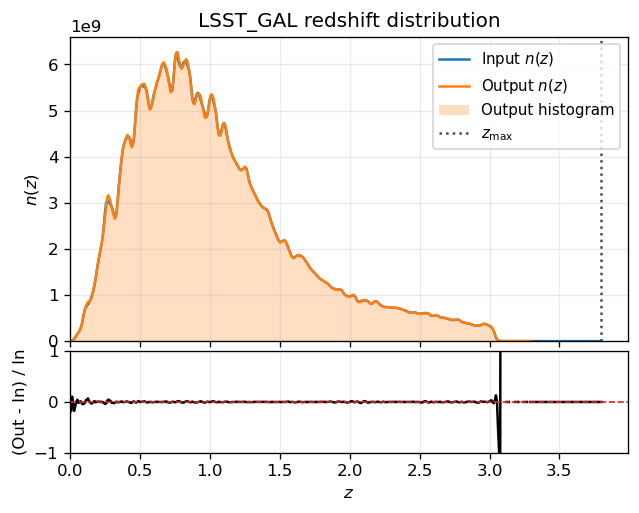

In [26]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1], 'hspace':0.05})

# Top panel
ax1.plot(z, nz_interp_input(z), 'C0-', lw=1.5, label=r'Input $n(z)$')
ax1.plot(z, nz_interp_output(z), 'C1-', lw=1.5, label=r'Output $n(z)$')
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C1', alpha=0.25, label='Output histogram')
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')

if galaxy_catalog != galaxy_catalog_bin:
    ax1.plot(z, nz_interp_output_bin(z)*norm_output_bin, 'C2-', lw=1.5, label=r'Output bin $n(z)$')
    ax1.bar(z_nz_output_bin, nz_output_bin, width=zbin_width_output_bin, align='center', color='C2', alpha=0.25, label='Output bin histogram')
    handles, labels = ax1.get_legend_handles_labels()
    order = [0, 1, 4, 3, 5, 2]
    ax1.legend([handles[i] for i in order], [labels[i] for i in order], frameon=True, loc='upper right', fontsize=9)
else:
    handles, labels = ax1.get_legend_handles_labels()
    order = [0, 1, 3, 2]
    ax1.legend([handles[i] for i in order], [labels[i] for i in order], frameon=True, loc='upper right', fontsize=9)

ax1.set_ylabel(r'$n(z)$')
ax1.set_title(f'{galaxy_catalog_bin.upper()} redshift distribution')
ax1.grid(alpha=0.25)


# Bottom panel
ratio = (nz_interp_output(z) - (nz_interp_input(z))) / nz_interp_input(z)
ratio = np.where(np.isnan(ratio), 0, ratio) # set to 0 if ratio is nan
ax2.plot(z, ratio, 'k', lw=1.5)
ax2.axhline(0, color='C3', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-1, 1)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - In) / In')
ax2.grid(alpha=0.25)

if galaxy_catalog != galaxy_catalog_bin:
    plt.savefig(f'../data/{box}/newplots/nz_{galaxy_catalog_bin}.png', dpi=300, bbox_inches='tight')
plt.show()

# First analysis: $\sigma_8$ and $b_g$ fit

The plan is to infer $\sigma_8$ by breaking the degeneracy with galaxy bias $b(z)$ by combining galaxy auto and galaxy x cmb lensing spectrums. However, we are working with $A_{\rm bias}$ instead of the bias directly, for validation purpouses, so we will be fitting for this parameter instead of the effective bias over the redshift bin $b_{\rm eff}$.

## camb init

In [27]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z
lmin, lmax = 2, 2500

In [28]:
# get cosmological parameters
cosmo_dict = load_cosmology(params_path)
z_max = cosmo_dict["z_max"]
sigma8_fid = cosmo_dict['sigma_8']
h_fid = cosmo_dict['h']

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=100,
    lmax=lmax,
    nonlinear=False
)

## data and covariance

In [29]:
kp = 1 / (2 / h_fid)  # smoothing scale in 1/Mpc, default value from the config file, corresponding to 2 Mpc/h
print(f"Default smoothing scale: kp = {kp:.3f} 1/Mpc")

Default smoothing scale: kp = 0.337 1/Mpc


In [30]:
scale_min = 40 / h_fid  # minimum scale in Mpc/h for fitting
lmax_fit = (2*np.pi) / scale_min * (results_lin.comoving_radial_distance(float(zmean)) / h_fid)  
lmax_fit = int(lmax_fit)  # maximum multipole for fitting, based on the minimum scale in Mpc/h
lmin_fit = 20  # minimum multipole for fitting, avoiding low multipoles where Limber and cosmic variance effects are significant
nbins_fit = 20  # number of multipole bins for fitting
print(f"Minimum multipole for galaxy fitting: lmin_fit = {lmin_fit}")
print(f"Maximum multipole for galaxy fitting: lmax_fit = {lmax_fit}")
print(f"Nº of multipole bins for galaxy fitting: nbins_fit = {nbins_fit}")

Minimum multipole for galaxy fitting: lmin_fit = 20
Maximum multipole for galaxy fitting: lmax_fit = 553
Nº of multipole bins for galaxy fitting: nbins_fit = 20


In [31]:
lmax_fit_kk = 1000  # maximum multipole for kk fitting
lmin_fit_kk = 20  # minimum multipole for fitting, avoiding low multipoles where Limber and cosmic variance effects are significant
nbins_fit_kk = 30  # number of multipole bins for fitting

In [32]:
# load and rebin gg data
box_path_gg = f'../data/{box}/cls/cl_gg_{galaxy_catalog_bin}.npz'
ells_gg_data, cls_gg_data, err_gg_data, nside_gg, shot_noise = get_colore_cls(box_path_gg)


# load and rebin kg data
box_path_kg = f'../data/{box}/cls/cl_kg_{galaxy_catalog_bin}.npz'
ells_kg_data, cls_kg_data, err_kg_data, nside_kg, shot_noise = get_colore_cls(box_path_kg)


# load and rebin kk data
box_path_kk = f'../data/{box}/cls/cl_kk.npz'
ells_kk_data, cls_kk_data, err_kk_data, nside_kk = get_colore_cls(box_path_kk, cmb_lensing=True)

# smooth with healpix pixel window function
pixwin_gg = hp.pixwin(nside_gg)
pixwin_kg = hp.pixwin(nside_kg)
pixwin_kk = hp.pixwin(nside_kk)

# rebin the theory to match the data
Bcov_gg = make_hybrid_bin_matrix(
    ells_gg_data,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

# rebin the theory to match the data
Bcov_kg = make_hybrid_bin_matrix(
    ells_kg_data,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

# rebin the theory to match the data
Bcov_kk = make_hybrid_bin_matrix(
    ells_kk_data,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

In [33]:
# rebin the data to match the theory
cls_gg_data_rebin = Bcov_gg @ cls_gg_data
cls_kg_data_rebin = Bcov_kg @ cls_kg_data
cls_kk_data_rebin = Bcov_kk @ cls_kk_data

# create data array and covariance matrix
cls_data = np.concatenate((cls_gg_data_rebin, cls_kg_data_rebin))

In [34]:
# compute and rebin covariance
fsky = 1
nl_gg = np.ones_like(ells_kg_data) * shot_noise
cross_cov = (2 / ((2*ells_kg_data + 1)*fsky)) * ((cls_gg_data[:len(ells_kg_data)] + nl_gg) * cls_kg_data)
var_gg = err_gg_data**2
var_kg = err_kg_data**2

# rebin the covariance matrix to match the data
cov_mat_gg_rebin = Bcov_gg @ np.diag(var_gg) @ Bcov_gg.T
cov_mat_kg_rebin = Bcov_kg @ np.diag(var_kg) @ Bcov_kg.T
cov_mat_kk_rebin = Bcov_kk @ np.diag(err_kk_data**2) @ Bcov_kk.T
cross_cov_rebin = Bcov_gg @ np.diag(cross_cov) @ Bcov_kg.T
rho_pearson_rebin = cross_cov_rebin / np.sqrt(np.diag(cov_mat_gg_rebin) * np.diag(cov_mat_kg_rebin))

# create the rebinned full covariance matrix
cov_mat = np.block([[cov_mat_gg_rebin, cross_cov_rebin],
                    [cross_cov_rebin.T, cov_mat_kg_rebin]])

# invert the covariance matrix
invcov_mat = np.linalg.inv(cov_mat)
invcov_mat_gg = np.linalg.inv(cov_mat_gg_rebin)
invcov_mat_kg = np.linalg.inv(cov_mat_kg_rebin)
invcov_mat_kk = np.linalg.inv(cov_mat_kk_rebin)

## theory

In [35]:
# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_tot',
    var2='delta_tot'
)

z_star = cosmo_dict["z_out"]
chi_star = results_lin.comoving_radial_distance(z_star)


# cosmological parameters needed by kernels
H0 = cosmo_dict["h"] * 100
om = cosmo_dict["omega_M"]

# shared kernel context
chi_source = chi_star
kernel_context = {
    "results": results_lin,
    "chi_source": chi_source,
    "cosmo_params": (H0, om),
}

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 200)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# add to kernel context for use in kernels and Limber integrand
kernel_context["chi"] = chi_grid
kernel_context["Hz"] = Hz_grid

# defined the kernel arguments 
kernel_args={
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output_bin}

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context, kernel_args)
Wg_grid = W_g(z_grid, kernel_context, kernel_args)

In [36]:
# multipoles and cls
ells = np.arange(lmin_fit, lmax_fit + 1)

# geometry
chi = kernel_context["chi"][:, None]        # (Nz,1)
Hz = kernel_context["Hz"][:, None]          # (Nz,1)
c_kms = c * 1e-3

# Limber k-grid (Nz, Nell)
k_grid = (ells[None, :] + 0.5) / chi
k2_grid = k_grid**2

# valid CAMB region
kmax = 100.0
mask = (k_grid > 1e-4) & (k_grid < kmax)

# evaluate P(k,z) for all z and ell
pk_lin = np.zeros_like(k_grid)
pk_lin[mask] = pk_interp_lin.P(
    np.broadcast_to(z_grid[:, None], k_grid.shape)[mask],
    k_grid[mask],
    grid=False,
)

# integrand without smoothing
base_gg = pk_lin * (c_kms / Hz) * (Wg_grid[:, None] * Wg_grid[:, None]) / chi**2
base_kg = pk_lin * (c_kms / Hz) * (Wk_grid[:, None] * Wg_grid[:, None]) / chi**2
base_kk = pk_lin * (c_kms / Hz) * (Wk_grid[:, None] * Wk_grid[:, None]) / chi**2

# match the healpix pixel window function with length of cls
lmax_map1 = len(pixwin_gg) - 1
lmax_map2 = len(pixwin_kg) - 1
lmax_min = np.min([lmax_map1, lmax_map2, lmax_fit])
pixwin_gg = pixwin_gg[lmin_fit : (lmax_min + 1)]
pixwin_kg = pixwin_kg[lmin_fit : (lmax_min + 1)]
ells = ells[:(lmax_min + 1 - lmin_fit)]

# rebin the theory to match the data
B = make_hybrid_bin_matrix(
    ells,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

# apply pixel window functions
B_gg = B * (pixwin_gg[None, :])**2
B_kg = B * (pixwin_kg[None, :])**2  
B_kk = B_kg.copy() # use kg pixel window for kk since they have the same nside

In [37]:
# Exact weights corresponding to scipy.integrate.simpson(..., x=z_grid)
simpson_weights = np.zeros(len(z_grid))

for i in range(len(z_grid)):
    basis = np.zeros(len(z_grid))
    basis[i] = 1.0
    simpson_weights[i] = simpson(basis, x=z_grid)

## likelihood evaluation timer

In [38]:
x0 = [1.0, sigma8_fid]  # initial guess for Abias, kp_gg, kp_kg, and sigma8
niter = 100 # number of iterations for timing the posterior evaluation
start_x0 = x0 + 1e-1 * np.random.randn(niter, len(x0))  # generate random starting points for each iteration
t = []

import time

for i in range(niter):
    t0 = time.perf_counter()
    value = log_posterior(
            start_x0[i],
            k2_grid,
            simpson_weights,
            base_gg,
            base_kg,
            B_gg,
            B_kg,
            cls_data,
            invcov_mat,
            sigma8_fid,
            kp
        )
    t.append(time.perf_counter() - t0)

print(f"posterior evaluation: {np.mean(t):.5f} s")

posterior evaluation: 0.00096 s


In [39]:
test = [1.0, 0.81]
log_posterior(
            test,
            k2_grid,
            simpson_weights,
            base_gg,
            base_kg,
            B_gg,
            B_kg,
            cls_data,
            invcov_mat,
            sigma8_fid,
            kp,
        )

np.float64(-475.06123784048157)

In [40]:
test = [1.0, 0.81]
log_posterior_single(
            test,
            get_limber_cls_fit_kg,
            k2_grid,
            simpson_weights,
            base_kg,
            B_kg,
            cls_kg_data_rebin,
            invcov_mat_kg,
            sigma8_fid,
            kp,
        )

np.float64(-9.46747767884664)

## Full sample

### minimizer & sampler

In [ ]:
# perform the chi2 minimization
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result = minimize(
    get_chi2,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_sigma8  = result.x
chi2_best = result.fun
reduced_chi2_best = result.fun/(nbins_fit-len(result.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.3f}")
print(f"Best-fit A_bias: {best_Abias:.3f}")
print(f"Chi2/ndof: {chi2_best:.2f}/({nbins_fit}-{len(result.x)}) = {reduced_chi2_best:.3f}")

In [ ]:
# scipy best fit as starting point for MCMC
theta0 = result.x

# initialize the MCMC
ndim = len(theta0)
nwalkers = 16  # number of walkers for MCMC, normally 3 times the number of dimensions

# small Gaussian scatter around the best-fit point
scatter = theta0 * [0.05, 0.05]  # scatter for Abias, kp_gg, kp_kg, and sigma8

# initialize walkers around best fit
start = theta0 + scatter * np.random.randn(nwalkers, ndim)

In [ ]:
# initialize the sampler
sampler = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior,
    args=(
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    ),
)

# run the MCMC
nsteps = 10000
sampler.run_mcmc(start, nsteps, progress=True)
sampler.summary

In [ ]:
# save the chains to a file
raw_chain = sampler.get_chain()

map_idx = np.argmax(sampler.get_log_prob(flat=True))
map_estimate = sampler.get_chain(flat=True)[map_idx]

truths = np.array([1.0, sigma8_fid])
np.savez(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", 
         chain=raw_chain, 
         nsteps=nsteps, nwalkers=nwalkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit, 
         map_estimate=map_estimate, bestfit_values=result.x, true_values=truths)

### visualization

In [ ]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps = 10000  # number of steps for MCMC

chain_file = np.load(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", allow_pickle=True)

chain = chain_file['chain']
nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
map_estimate = chain_file['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)
axis_labels = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

for i in range(ndim):
    for walker in range(chain.shape[1]):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, len(chain))
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

In [ ]:
chain[200, :, -1]

In [ ]:
# declare the burnin and deleted walkers for each chain
burnin = 500
deleted_walkers = np.array([]).astype(int)  # indices of walkers to delete

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain = np.delete(chain, obj=deleted_walkers, axis=1)
clean_chain = clean_chain[burnin:, : , :]  # discard the first burnin steps
clean_samples = clean_chain.reshape(-1, clean_chain.shape[-1])  # reshape to 2D array for corner plot

# save the cleaned chains to a file
np.savez(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", 
         chain=chain, clean_samples=clean_samples, 
         nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit, 
         map_estimate=map_estimate, bestfit_values=bestfit_values, true_values=truths)

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)

for i in range(ndim):
    for walker in range(nwalkers-len(deleted_walkers)):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(clean_chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, clean_chain.shape[0])
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

### plotter

In [97]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps = 10000  # number of steps for MCMC
nsteps_single = 10000  # number of steps for MCMC
nsteps_kk = 2000  # number of steps for MCMC

In [98]:
# load the chains from the file 
chain_file = np.load(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", allow_pickle=True)
chain_file_gg = np.load(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}.npz", allow_pickle=True)
chain_file_kk = np.load(f"../data/{box}/newchains/chain_kk_nsteps{nsteps_kk}.npz", allow_pickle=True)

# extract the chain and samples
chain = chain_file['chain']
samples = chain_file['clean_samples']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']
samples_kk = chain_file_kk['clean_samples']

# extract the chain parameters
nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
deleted_walkers = chain_file['deleted_walkers']
burnin = chain_file['burnin']

# load the MAP estimate, best-fit values, and true values
map_estimate = chain_file['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

In [99]:
# extract the fitting parameters for the joint and single datasets
lmin_fit = chain_file['lmin_fit']
lmax_fit = chain_file['lmax_fit']
nbins_fit = chain_file['nbins_fit']

lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the joint analysis:")
print(f"lmin_fit: {lmin_fit}, lmax_fit: {lmax_fit}, nbins_fit: {nbins_fit}")
print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

Fitting parameters for the joint analysis:
lmin_fit: 20, lmax_fit: 553, nbins_fit: 20
Fitting parameters for the CMB lensing auto analysis:
lmin_fit: 20, lmax_fit: 1000, nbins_fit: 30


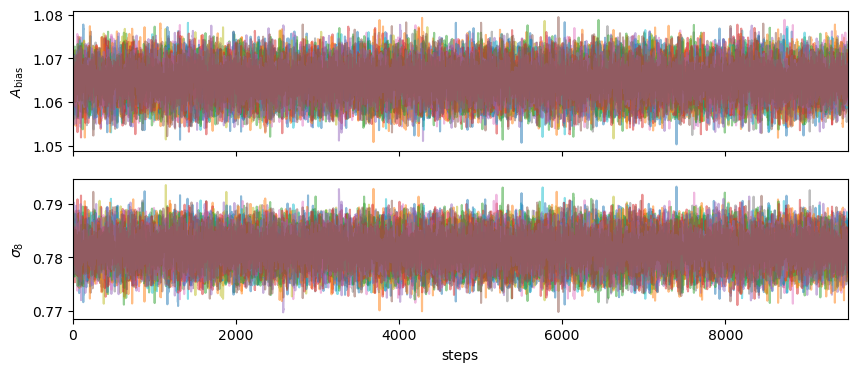

In [100]:
axis_labels = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)

for i in range(ndim):
    for walker in np.delete(np.arange(nwalkers), deleted_walkers):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[burnin:, walker, i], alpha=0.5)
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

In [101]:
# get the getdist samples for the joint analysis and the single analyses
cat_name = format_catalog_name(galaxy_catalog_bin)  # Format the galaxy string dynamically

names = ["Abias", "sigma8"]
labels = [r"A_{\rm bias}", r"\sigma_8"]

legend_labels = [r"Joint Constraints ($g \times g$ + $\kappa \times g$)", 
    r"CMB lensing ($\kappa \times \kappa$)",
    rf"{cat_name} ($g \times g$)", 
    rf"CMB lensing $\times$ {cat_name} ($\kappa \times g$)"
]

samples_gd = MCSamples(samples=samples, names=names, labels=labels)
samples_gg_gd = MCSamples(samples=samples_gg, names=names, labels=labels)
samples_kg_gd = MCSamples(samples=samples_kg, names=names, labels=labels)
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


In [102]:
# get CMB lensing auto constraints
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly
sigma8_kk = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err  # This is the 1-sigma standard deviation

In [103]:
# reverse the order of the samples and colors for plotting
sample_list = [samples_gd, samples_kk_gd, samples_gg_gd, samples_kg_gd]
color_list = ["C0", "C4", "C1", "C2"]

sample_list_reversed = sample_list[::-1]
color_list_reversed = color_list[::-1]
legend_labels_reversed = legend_labels[::-1]

auto bandwidth for sigma8 very small or failed (h=0.000778356541223404,N_eff=152000.0). Using fallback (h=0.0179545215748794)
fine_bins_2D not large enough for optimal density: Abias, sigma8


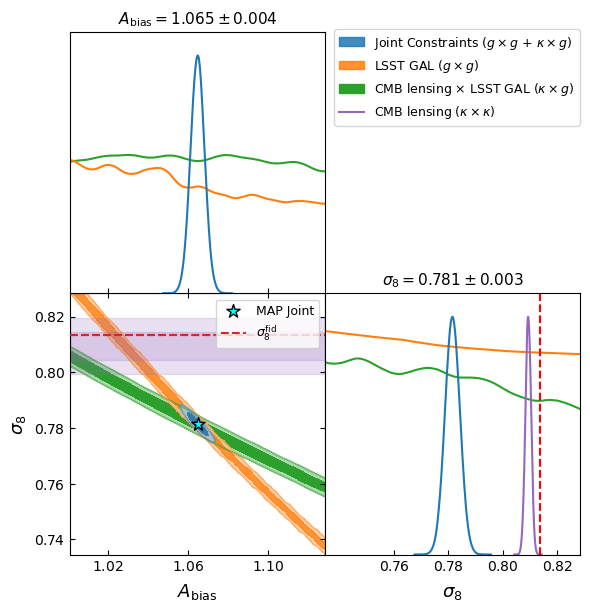

In [104]:
g = plots.get_subplot_plotter(subplot_size=3)
g.settings.legend_fontsize = 10
f_min = 0.94
f_max = 1.06

g.triangle_plot(sample_list_reversed,
                filled=True,
                title_limit=0,
                contour_colors=color_list_reversed,
                contour_lws=1.5,
                param_limits={'Abias': (map_estimate[0]*f_min, map_estimate[0]*f_max), 'sigma8': (map_estimate[1]*f_min, map_estimate[1]*f_max)})
g.add_param_markers({'sigma8': sigma8_fid}, color='red', ls='--', lw=1.5)
g.fig.legends = [] 

# add titles to the subplots from the joint analysis
title_Abias = samples_gd.getLatex('Abias', limit=1, err_sig_figs=1)
title_sigma8 = samples_gd.getLatex('sigma8', limit=1, err_sig_figs=1)
g.subplots[0, 0].set_title(f"${title_Abias}$", fontsize=11)
g.subplots[1, 1].set_title(f"${title_sigma8}$", fontsize=11)

ax = g.subplots[1, 0]

ax.scatter(map_estimate[0], map_estimate[-1], color='cyan', marker="*", edgecolors='k', s=100, label="MAP Joint", zorder=5)
#ax.axvline(truths[0], color="C3", ls="--", lw=1, zorder=4, label=r"$A_{\rm bias}$ true")
ax.axhline(truths[-1], color="C3", ls="--", lw=1.5, zorder=4, label=r"$\sigma_8^{\mathrm{fid}}$")
#ax.axhline(sigma8_kk, color='C4', ls='-', lw=1.5)
g.add_y_bands(y=sigma8_kk, sigma=0.005, color='C4', ax=ax, alpha1=0.2, alpha2=0.2)

ax.legend(loc="upper right", fontsize=9, frameon=True)

g.add_legend(legend_labels=legend_labels_reversed, 
             figure=True,
             bbox_to_anchor=(0.77, 0.99),
             label_order=[3, 1, 0, 2])  # <-- This flips the layout order inside the legend box!

plt.savefig(
    f"../data/{box}/newchains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}.png",
    dpi=500,
    bbox_inches="tight")
plt.savefig(
    f"../data/{box}/newchains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}.pdf",
    dpi=500,
    bbox_inches="tight")
plt.show()

## Single dataset

### minimizer-sampler

In [41]:
# perform the chi2 minimization for gg data
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result_gg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_gg,
        k2_grid,
        simpson_weights,
        base_gg,
        B_gg,
        cls_gg_data_rebin,
        invcov_mat_gg,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_sigma8  = result_gg.x
chi2_best = result_gg.fun
reduced_chi2_best = result_gg.fun/(nbins_fit-len(result_gg.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.3f}")
print(f"Best-fit A_bias: {best_Abias:.3f}")
print(f"Chi2/ndof: {chi2_best:.2f}/{nbins_fit-len(result_gg.x)} = {reduced_chi2_best:.3f}")

Best-fit sigma8: 0.825
Best-fit A_bias: 1.009
Chi2/ndof: 131.93/18 = 7.329


In [42]:
# perform the chi2 minimization for kg data
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result_kg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_kg,
        k2_grid,
        simpson_weights,
        base_kg,
        B_kg,
        cls_kg_data_rebin,
        invcov_mat_kg,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_sigma8  = result_kg.x
chi2_best = result_kg.fun
reduced_chi2_best = result_kg.fun/(nbins_fit-len(result_kg.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.3f}")
print(f"Best-fit A_bias: {best_Abias:.3f}")
print(f"Chi2/ndof: {chi2_best:.2f}/{nbins_fit-len(result_kg.x)} = {reduced_chi2_best:.3f}")

Best-fit sigma8: 0.809
Best-fit A_bias: 0.993
Chi2/ndof: 13.67/18 = 0.760


In [43]:
# perform the chi2 minimization for kk data
bounds = [0.5, 1.5]  # bounds for sigma8
result_kk = minimize_scalar(
    get_chi2_single,
    bounds=bounds,
    method='bounded',
    args=(
        get_limber_cls_fit_kk,
        k2_grid,
        simpson_weights,
        base_kk,
        B_kg,
        cls_kk_data_rebin,
        invcov_mat_kk,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_sigma8  = result_kk.x
chi2_best = result_kk.fun
reduced_chi2_best = result_kk.fun/(nbins_fit-1)  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.3f}")
print(f"Chi2/ndof: {chi2_best:.2f}/{nbins_fit-1} = {reduced_chi2_best:.3f}")

Best-fit sigma8: 0.809
Chi2/ndof: 26.16/19 = 1.377


In [44]:
# scipy best fit as starting point for MCMC
theta0_gg = result_gg.x
theta0_kg = result_kg.x
theta0_kk = result_kk.x

# initialize the MCMC
ndim = len(theta0_gg)
ndim_kk = 1
nwalkers = 16  # number of walkers for MCMC, normally 3 times the number of dimensions
nwalkers_kk = 8  # number of walkers for MCMC, normally 3 times the number of dimensions

# small Gaussian scatter around the best-fit point
scatter_gg = theta0_gg * 0.05  # scatter for Abias and sigma8
scatter_kg = theta0_kg * 0.05  # scatter for Abias and sigma8
scatter_kk = theta0_kk * 0.05  # scatter for sigma8

# initialize walkers around best fit
start_gg = theta0_gg + scatter_gg * np.random.randn(nwalkers, ndim)
start_kg = theta0_kg + scatter_kg * np.random.randn(nwalkers, ndim)
start_kk = theta0_kk + scatter_kk * np.random.randn(nwalkers_kk, ndim_kk)

In [45]:
# initialize the gg sampler
sampler_gg = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior_single,
    args=(
        get_limber_cls_fit_gg,
        k2_grid,
        simpson_weights,
        base_gg,
        B_gg,
        cls_gg_data_rebin,
        invcov_mat_gg,
        sigma8_fid,
        kp,
        )
)

# initialize the kg sampler
sampler_kg = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kg,
        k2_grid,
        simpson_weights,
        base_kg,
        B_kg,
        cls_kg_data_rebin,
        invcov_mat_kg,
        sigma8_fid,
        kp,
        )
)

# initialize the kk sampler
sampler_kk = zeus.EnsembleSampler(
    nwalkers_kk,
    ndim_kk,
    log_posterior_kk,
    args=(
        k2_grid,
        simpson_weights,
        base_kk,
        B_kk,
        cls_kk_data_rebin,
        invcov_mat_kk,
        sigma8_fid,
        kp,
        )
)

In [46]:
# define number of steps for MCMC
nsteps_single = 10000
nsteps_kk = 2000

In [ ]:
# run the gg MCMC
sampler_gg.run_mcmc(start_gg, nsteps_single, progress=True)
sampler_gg.summary

In [ ]:
# run the kg MCMC
sampler_kg.run_mcmc(start_kg, nsteps_single, progress=True)
sampler_kg.summary

In [ ]:
# save the gg/kg chains to a file 
raw_chain_gg = sampler_gg.get_chain()
raw_chain_kg = sampler_kg.get_chain()

map_idx_gg = np.argmax(sampler_gg.get_log_prob(flat=True))
map_estimate_gg = sampler_gg.get_chain(flat=True)[map_idx_gg]
map_idx_kg = np.argmax(sampler_kg.get_log_prob(flat=True))
map_estimate_kg = sampler_kg.get_chain(flat=True)[map_idx_kg]
truths = np.array([1.0, sigma8_fid])

np.savez(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}.npz", 
         chain=raw_chain_gg, nsteps=nsteps_single, 
         nwalkers=nwalkers, ndim=ndim,
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_gg, bestfit_values=result_gg.x, true_values=truths)
np.savez(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}.npz", 
         chain=raw_chain_kg, 
         nsteps=nsteps_single, nwalkers=nwalkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_kg, bestfit_values=result_kg.x, true_values=truths)

In [47]:
# run the kk MCMC
sampler_kk.run_mcmc(start_kk, nsteps_kk, progress=True)
sampler_kk.summary

Initialising ensemble of 8 walkers...
Sampling progress : 100%|██████████| 2000/2000 [00:47<00:00, 41.95it/s]
Summary
-------
Number of Generations: 2000
Number of Parameters: 1
Number of Walkers: 8
Number of Tuning Generations: 36
Scale Factor: 2.213733
Mean Integrated Autocorrelation Time: 0.96
Effective Sample Size: 16746.0
Number of Log Probability Evaluations: 128723
Effective Samples per Log Probability Evaluation: 0.130093


In [49]:
# save the kk chains to a file 
raw_chain_kk = sampler_kk.get_chain()

map_idx_kk = np.argmax(sampler_kk.get_log_prob(flat=True))
map_estimate_kk = sampler_kk.get_chain(flat=True)[map_idx_kk]
truths = np.array([1.0, sigma8_fid])

np.savez(f"../data/{box}/newchains/chain_kk_nsteps{nsteps_kk}.npz", 
         chain=raw_chain_kk, 
         nsteps=nsteps_kk, nwalkers=nwalkers_kk, ndim=ndim_kk, 
         lmin_fit=lmin_fit_kk, lmax_fit=lmax_fit_kk, nbins_fit=nbins_fit_kk,
         map_estimate=map_estimate_kk, bestfit_values=result_kk.x, true_values=truths[-1])

### visualization

In [50]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 10000
nsteps_kk = 2000

chain_filename_gg = f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}.npz"
chain_filename_kg = f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}.npz"
chain_filename_kk = f"../data/{box}/newchains/chain_kk_nsteps{nsteps_kk}.npz"
chain_file_gg = np.load(chain_filename_gg, allow_pickle=True)
chain_file_kg = np.load(chain_filename_kg, allow_pickle=True)
chain_file_kk = np.load(chain_filename_kk, allow_pickle=True)
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
chain_kk = chain_file_kk['chain']

nsteps = chain_file_gg['nsteps']
nsteps_kk = chain_file_kk['nsteps']
nwalkers = chain_file_gg['nwalkers']
nwalkers_kk = chain_file_kk['nwalkers']
ndim = chain_file_gg['ndim']
ndim_kk = chain_file_kk['ndim']
lmin_fit = chain_file_gg['lmin_fit']
lmax_fit = chain_file_gg['lmax_fit']
lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit = chain_file_gg['nbins_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
bestfit_values_kk = chain_file_kk['bestfit_values']
truths = chain_file_gg['true_values']

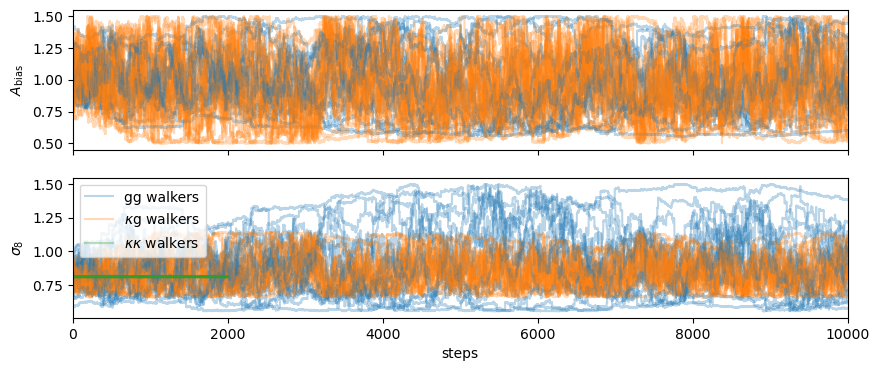

In [54]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)

axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

for i in range(ndim):
    ax = axes[i]
    for walker in range(chain_gg.shape[1]):
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain_gg[:, walker, i], c='C0', alpha=0.3, label="gg walkers" if walker == 0 else "")
        ax.plot(chain_kg[:, walker, i], c='C1', alpha=0.3, label=r"$\kappa$g walkers" if walker == 0 else "")

    ax.set_xlim(0, len(chain_gg))
    ax.set_ylabel(axis_labels_single[i])

for walker in range(chain_kk.shape[1]):
    axes[-1].plot(chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r"$\kappa \kappa$ walkers" if walker == 0 else "")

axes[-1].set_xlabel('steps')
axes[-1].legend()
plt.show()

In [52]:
# declare the burnin and deleted walkers for each chain
burnin = 500
deleted_walkers_gg = np.array([]).astype(int)  # indices of walkers to delete for gg
deleted_walkers_kg = np.array([]).astype(int)  # indices of walkers to delete for kg
deleted_walkers_kk = np.array([]).astype(int)  # indices of walkers to delete for kk

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain_gg = np.delete(chain_gg, obj=deleted_walkers_gg, axis=1)
clean_chain_kg = np.delete(chain_kg, obj=deleted_walkers_kg, axis=1)
clean_chain_kk = np.delete(chain_kk, obj=deleted_walkers_kk, axis=1) 
clean_chain_gg = clean_chain_gg[burnin:, : , :]  # discard the first burnin steps as burn-in
clean_chain_kg = clean_chain_kg[burnin:, : , :]
clean_chain_kk = clean_chain_kk[burnin:, : , :]
clean_samples_gg = clean_chain_gg.reshape(-1, clean_chain_gg.shape[-1])  # reshape to 2D array for corner plot
clean_samples_kg = clean_chain_kg.reshape(-1, clean_chain_kg.shape[-1])
clean_samples_kk = clean_chain_kk.reshape(-1, clean_chain_kk.shape[-1])

# save the cleaned chains to a file
np.savez(chain_filename_gg, 
         chain=chain_gg, clean_samples=clean_samples_gg, 
         nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers_gg, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_gg, bestfit_values=bestfit_values_gg, true_values=truths)
np.savez(chain_filename_kg, 
         chain=chain_kg, clean_samples=clean_samples_kg, 
         nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers_kg, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_kg, bestfit_values=bestfit_values_kg, true_values=truths)
np.savez(chain_filename_kk, 
         chain=chain_kk, clean_samples=clean_samples_kk, 
         nsteps=nsteps_kk, burnin=burnin, nwalkers=nwalkers_kk, deleted_walkers=deleted_walkers_kk, ndim=ndim_kk, 
         lmin_fit=lmin_fit_kk, lmax_fit=lmax_fit_kk, nbins_fit=nbins_fit_kk,
         map_estimate=map_estimate_kk, bestfit_values=bestfit_values_kk, true_values=truths[-1])

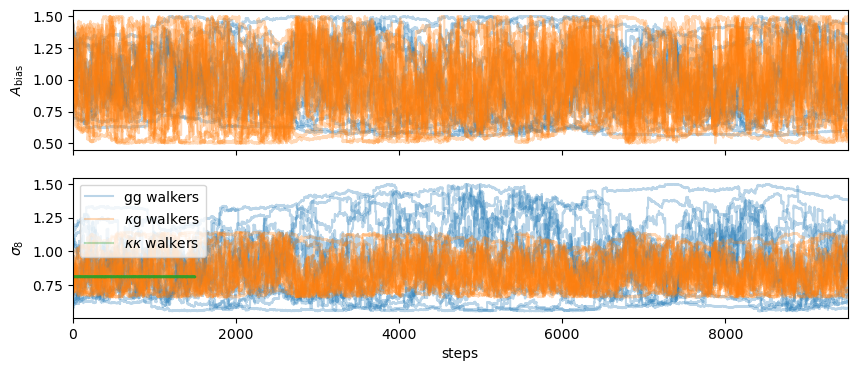

In [55]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)

for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker in range(clean_chain_gg.shape[1]):
        ax.plot(clean_chain_gg[:, walker, i], c='C0', alpha=0.3, label='gg walkers' if walker == 0 else "")
    for walker in range(clean_chain_kg.shape[1]):
        ax.plot(clean_chain_kg[:, walker, i], c='C1', alpha=0.3, label=r'$\kappa$g walkers' if walker == 0 else "")
    ax.set_xlim(0, clean_chain_gg.shape[0])
    ax.set_ylabel(axis_labels_single[i])
                  
for walker in range(clean_chain_kk.shape[1]):
    ax.plot(clean_chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r'$\kappa\kappa$ walkers' if walker == 0 else "")

axes[-1].set_xlabel('steps')
axes[-1].legend()
plt.show()

### plotter

In [90]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 10000  # number of steps for MCMC
nsteps_kk = 2000  # number of steps for MCMC

# load the chains from the file 
chain_file_gg = np.load(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/newchains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}.npz", allow_pickle=True)
chain_file_kk = np.load(f"../data/{box}/newchains/chain_kk_nsteps{nsteps_kk}.npz", allow_pickle=True)

# extract the chain and samples
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
chain_kk = chain_file_kk['chain']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']
samples_kk = chain_file_kk['clean_samples']

# extract the chain parameters
nsteps = chain_file_gg['nsteps']
nwalkers = chain_file_gg['nwalkers']
nwalkers_kk = chain_file_kk['nwalkers']
ndim = chain_file_gg['ndim']
deleted_walkers_gg = chain_file_gg['deleted_walkers']
deleted_walkers_kg = chain_file_kg['deleted_walkers']
deleted_walkers_kk = chain_file_kk['deleted_walkers']
burnin = chain_file_gg['burnin']  # they should be equal, otherwise the uncertainty intervals comparison is not fair

# load the MAP estimate, best-fit values, and true values
map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
truths = chain_file_gg['true_values']

In [91]:
# extract the fitting parameters for the gg/kg and kk single datasets
lmin_fit = chain_file_gg['lmin_fit']
lmax_fit = chain_file_gg['lmax_fit']
nbins_fit = chain_file_gg['nbins_fit']

lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the gg/kg analysis:")
print(f"lmin_fit: {lmin_fit}, lmax_fit: {lmax_fit}, nbins_fit: {nbins_fit}")
print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

Fitting parameters for the gg/kg analysis:
lmin_fit: 20, lmax_fit: 553, nbins_fit: 20
Fitting parameters for the CMB lensing auto analysis:
lmin_fit: 20, lmax_fit: 1000, nbins_fit: 30


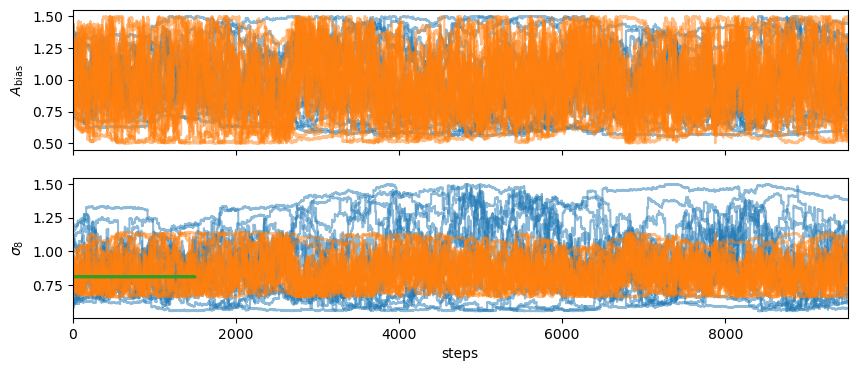

In [92]:
axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)
for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    for walker in np.delete(np.arange(nwalkers), obj=deleted_walkers_gg, axis=0):
        ax = axes[i]
        ax.plot(chain_gg[burnin:, walker, i], c="C0", alpha=0.5)
    for walker in np.delete(np.arange(nwalkers), obj=deleted_walkers_kg, axis=0):
        ax = axes[i]
        ax.plot(chain_kg[burnin:, walker, i], c="C1", alpha=0.5)
    for walker in np.delete(np.arange(nwalkers_kk), obj=deleted_walkers_kk, axis=0):
        axes[-1].plot(chain_kk[burnin:, walker, -1], c="C2", alpha=0.5)
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels_single[i])
    axes[-1].set_xlabel('steps')

In [93]:
# get the getdist samples for the joint analysis and the single analyses
cat_name = format_catalog_name(galaxy_catalog_bin)  # Format the galaxy string dynamically

names = ["Abias", "sigma8"]
labels = [r"A_{\rm bias}", r"\sigma_8"]

legend_labels = [
    rf"{cat_name} ($g \times g$)", 
    rf"CMB lensing $\times$ {cat_name} ($\kappa \times g$)", 
    r"CMB lensing ($\kappa \times \kappa$)"
]

samples_gg_gd = MCSamples(samples=samples_gg, names=names, labels=labels)
samples_kg_gd = MCSamples(samples=samples_kg, names=names, labels=labels)
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

Removed no burn in
Removed no burn in
Removed no burn in


In [94]:
# get CMB lensing auto constraints
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly
sigma8_kk = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err  # This is the 1-sigma standard deviation

In [95]:
# get the sample and color lists for plotting
sample_list = [samples_gg_gd, samples_kg_gd, samples_kk_gd]
color_list = ["C1", "C2", "C4"]

auto bandwidth for sigma8 very small or failed (h=0.000778356541223404,N_eff=152000.0). Using fallback (h=0.0179545215748794)
fine_bins_2D not large enough for optimal density: Abias, sigma8
auto bandwidth for sigma8 very small or failed (h=0.000778356541223404,N_eff=152000.0). Using fallback (h=0.0179545215748794)


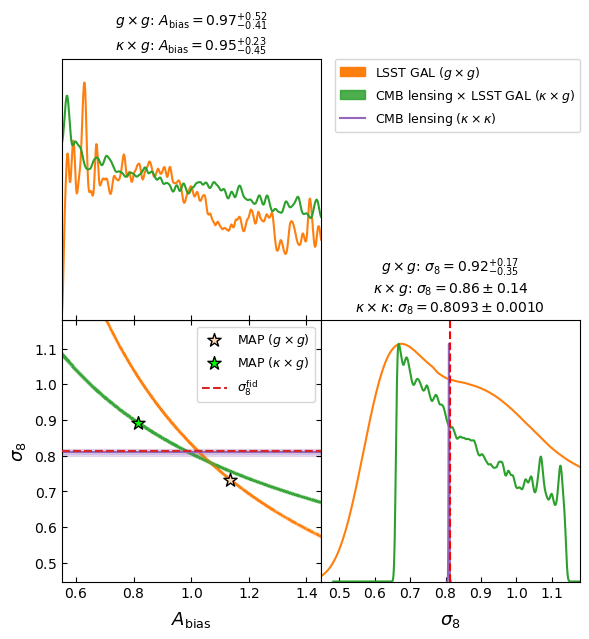

In [96]:
g = plots.get_subplot_plotter(subplot_size=3)
g.settings.legend_fontsize = 10
f_min = 0.55
f_max = 1.45

g.triangle_plot(sample_list,
                filled=True,
                legend_labels=legend_labels,
                contour_colors=color_list,
                contour_lws=1.5,
                param_limits={'Abias': (truths[0]*f_min, truths[0]*f_max), 'sigma8': (truths[1]*f_min, truths[1]*f_max)})
g.add_param_markers({'sigma8': sigma8_fid}, color='red', ls='--', lw=1.5)

ax = g.subplots[1, 0]

s0, s1, s2 = sample_list[0], sample_list[1], sample_list[2]

title_Abias_0 = s0.getInlineLatex('Abias', limit=1)
title_Abias_1 = s1.getInlineLatex('Abias', limit=1)

title_sigma8_0 = s0.getInlineLatex('sigma8', limit=1)
title_sigma8_1 = s1.getInlineLatex('sigma8', limit=1)
title_sigma8_2 = s2.getInlineLatex('sigma8', limit=1)

g.subplots[0, 0].set_title(
    f"{(r"$g \times g$")}: ${title_Abias_0}$\n{(r"$\kappa \times g$")}: ${title_Abias_1}$", 
    fontsize=10
)

g.subplots[1, 1].set_title(
    f"{(r"$g \times g$")}: ${title_sigma8_0}$\n{(r"$\kappa \times g$")}: ${title_sigma8_1}$\n{(r"$\kappa \times \kappa$")}: ${title_sigma8_2}$", 
    fontsize=10
)

ax.scatter(map_estimate_gg[0], map_estimate_gg[-1], color='peachpuff', marker="*", edgecolors='k', s=100, label=r"MAP ($g \times g$)", zorder=5)
ax.scatter(map_estimate_kg[0], map_estimate_kg[-1], color='lime', marker="*", edgecolors='k', s=100, label=r"MAP ($\kappa \times g$)", zorder=5)
#ax.axvline(truths[0], color="C3", ls="--", lw=1, zorder=4, label=r"$A_{\rm bias}$ true")
ax.axhline(truths[-1], color="C3", ls="--", lw=1.5, zorder=4, label=r"$\sigma_8^{\mathrm{fid}}$")
ax.axhline(sigma8_kk, color='C4', ls='-', lw=1.5)
g.add_y_bands(y=sigma8_kk, sigma=0.005, color='C4', ax=ax, alpha1=0.2, alpha2=0.2)

ax.legend(loc="upper right", fontsize=9, frameon=True)

plt.savefig(
    f"../data/{box}/newchains/corner_plot_{galaxy_catalog_bin}_single_nsteps{nsteps}.png",
    dpi=500,
    bbox_inches="tight")
plt.savefig(
    f"../data/{box}/newchains/corner_plot_{galaxy_catalog_bin}_single_nsteps{nsteps}.pdf",
    dpi=500,
    bbox_inches="tight")
plt.show()